# Numerical plots for fixed-point search

Reference: [manuscript dated November 7, 2026](../docs/manuscript-2026-11-07.pdf).
This notebook produces the numerical plots associated with Figs. 3, 5, 6 and 7,
plus a separate check of the two-check bound. It does not draw the circuit figures.

The M-dependent cutoff used in the manuscript plots is different from Algorithm 1's
fixed N-based schedule. Eq. (35) sums successful stopping events; the all-attempt
mean also charges failed attempts. Each curve below names its convention.
The guarantee budget is not the maximum cost of every attempt.


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
codes = Path.cwd() if (Path.cwd()/"search_model.py").exists() else Path.cwd()/"Codes"
sys.path.insert(0, str(codes.resolve()))
from make_figures import make_figures
figures, rows = make_figures(N=10**10)


## Cost comparison

Epsilon follows Eq. (6). These are unweighted ratios over the plotted grid,
not a proof of a universal 1.33 factor. The zero-solution case belongs to the
fixed schedule and is checked by `verify_updated.py`.


In [2]:
values = np.asarray(rows)
for name, column in [("Figure cutoff: Eq. (35) sum", 4),
                     ("Figure cutoff: all attempts", 5),
                     ("Fixed schedule: all attempts", 6)]:
    ratio = values[:, column]/values[:, 1]
    print(f"{name}: min={ratio.min():.6f}, mean={ratio.mean():.6f}, max={ratio.max():.6f}")


Figure cutoff: Eq. (35) sum: min=1.163672, mean=1.257464, max=1.543595
Figure cutoff: all attempts: min=1.279986, mean=1.326455, max=1.559233
Fixed schedule: all attempts: min=1.283180, mean=1.465243, max=1.743849


fig5_probability
fig7_oraclecalls
fig6_cumulative
fig3_souffle
diagnostic_two_check_bound


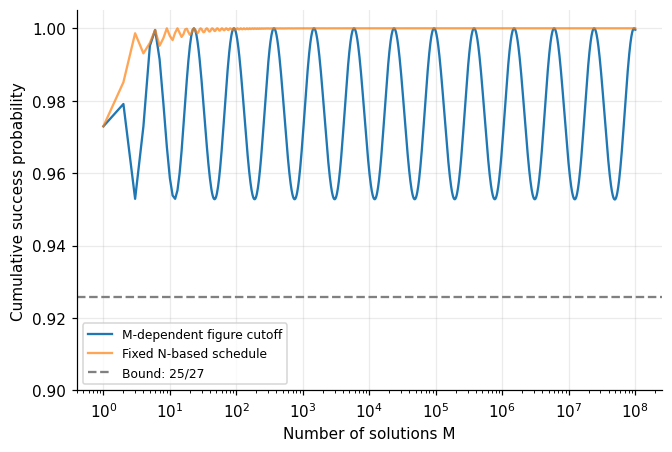

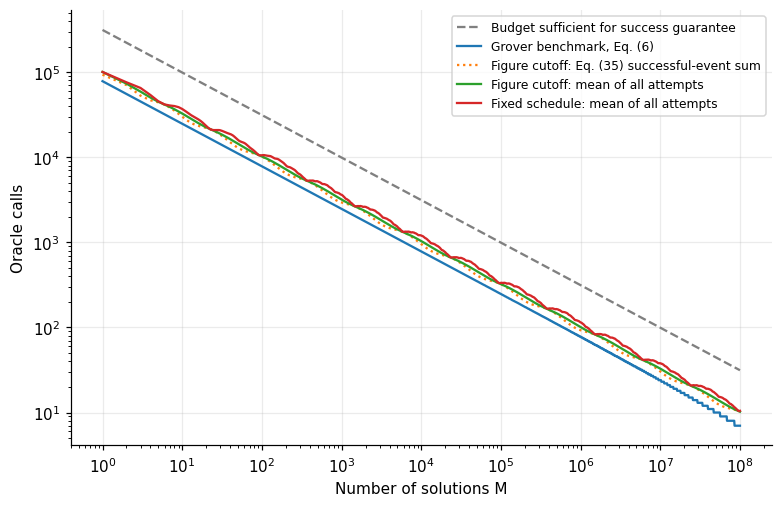

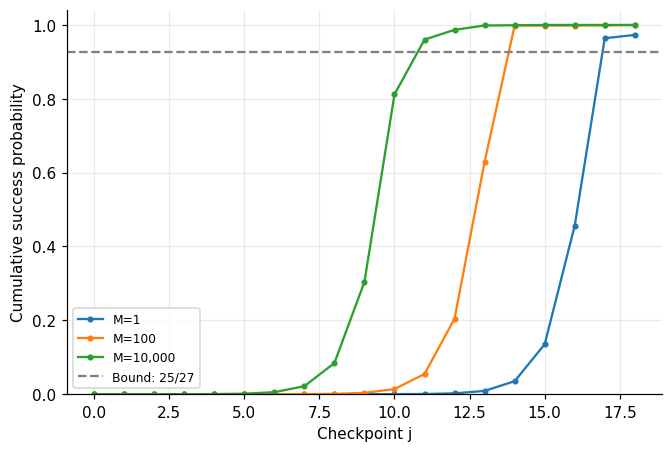

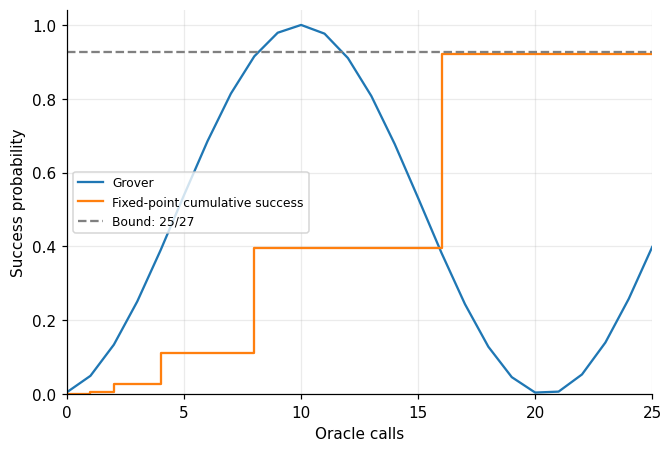

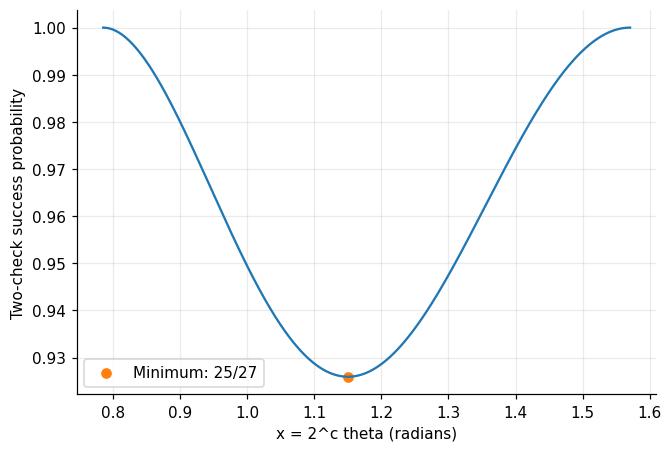

In [3]:
for name, figure in figures.items():
    print(name)
    display(figure)
    plt.close(figure)


To export PNG and PDF figures with their data, run from the repository root:

```bash
python Codes/make_figures.py --output research_results
```

The plots include explanatory comparisons beyond the manuscript's original curves.
See [research notes](../docs/research.md) for the figure mapping.
